![ECMWF](../logo.png)

# ECMWF Tropical Cyclone Track Archive: tropical cyclone Garance showcase

This notebook shows how to access and plot the **Tropical cyclone tracks** data directly from the ECMWF static dataset hosted on AWS S3. For reference, the closest operational chart product is [Tropical cyclone plumes](https://charts.ecmwf.int/products/cyclone?product=tc_plumes).

This notebook uses the Garance tropical cyclone to show what an ECMWF tropical cyclone track forecast contains and what can be read from it.

***Garance** was a tropical cyclone that formed east of Madagascar in late February 2025, reached intense tropical cyclone strength on the 27th and crossed Réunion from north to south on the morning of the 28th. It killed five people and left much of the island without power and water, and the 214 km/h gust recorded at Réunion's main airport was the strongest measured there since 1962.*

## Settings

This notebook follows the example of Garance Tropical Cyclone. If you wish to follow a different storm or start from a
different forecast run, change these values and run the notebook again.

In [1]:
from datetime import datetime, timedelta

# ---- which storm, and which forecast run to start from ----------------------
# give a name or an identifier; the name is used when both are set
STORM_NAME = "GARANCE"             # longStormName in the file
STORM_ID = None                    # stormIdentifier, e.g. "10S", for unnamed systems
BASE_TIME = "20250225T120000"      # YYYYMMDDTHHMMSS, a 00/12 runs before 2017-03-23 12 UTC, 00/06/12/18 runs after 2017-03-23 18 UTC
BASE = datetime.strptime(BASE_TIME, "%Y%m%dT%H%M%S")

# ---- optional: a place the storm threatens; set PLACE to None to leave it out
PLACE_NAME = "Réunion"
PLACE = (-21.115, 55.536)          # latitude, longitude

# ---- optional: what was observed; set to None if you do not have it ---------
LANDFALL = datetime(2025, 2, 28, 6)
OBSERVED_MSLP, OBSERVED_WIND = 975.0, 85.0     # hPa and knots

## 1. Data Processing

> *On 25 February 2025 at 10 UTC, a tropical depression near Madagascar intensified into a moderate tropical storm and was named **Garance** by the Malagasy meteorological service.*

Let's examine a **Tropical Cyclone Track** forecast from the 25/02/2025 12 UTC run. It was issued right after Garance received its name.

### 1.1. Download the data from S3

This notebook needs [earthkit-data](https://earthkit-data.readthedocs.io/en/latest/index.html) to read the BUFR file, together with `pandas`, `matplotlib` and `cartopy`. 
To install it in your kernel, uncomment and run the cell below.

In [2]:
#!pip install "earthkit-data>=1.0" pandas matplotlib cartopy

ECMWF publishes a number of open datasets in the public **`ecmwf-static-datasets`** bucket on Amazon S3. The tropical cyclone track files live under `tropical-cyclone-tracks/<year>/<month>/`, and no account or credentials are needed to read them.

`ekd.from_source("s3", ...)` fetches the object and keeps it in the earthkit cache.

In [3]:
import earthkit.data as ekd


def run_file(base_time):
    """S3 request for the tropical cyclone track file of one ensemble run."""
    base = datetime.strptime(base_time, "%Y%m%dT%H%M%S")
    hours = 360 if base.hour in (0, 12) else 144   # the 00 and 12 UTC runs go further ahead
    end = base + timedelta(hours=hours)
    name = (f"ecm_wf_ifs-ens_od_enfo_tf"
            f"_{base:%Y%m%dT%H%M%S}Z_{end:%Y%m%dT%H%M%S}Z_{hours}h.bufr")
    return {
        "endpoint": "s3.eu-central-1.amazonaws.com",
        "bucket": "ecmwf-static-datasets",
        "objects": f"tropical-cyclone-tracks/{base:%Y/%m}/{name}",
    }


ds = ekd.from_source("s3", run_file(BASE_TIME), anon=True)

ecm_wf_ifs-ens_od_enfo_tf_20250225T120000Z_20250312T120000Z_360h.bufr:   0%|          | 0.00/1.32M [00:00<?, ?…

--------------------------

### 1.2. Read the BUFR file
To inspect BUFR data we need to convert it into a FeatureList. 

In [4]:
fl = ds.to_featurelist()
len(fl)

54

The FeatureList has a length of 54, meaning the BUFR file contains 54 tropical cyclone feature reports. Only a small portion of them are named tropical cyclones. A feature carries a name when the cyclone had already been observed — reported by a WMO centre — at the initial time of the forecast, and the ensemble also has it. Everything else is a system the tracker found in the forecast alone; those keep a plain identifier such as `70S` instead of a name.

We can call **head()**, **tail()** or **ls()** to see metadata from the header section of the BUFR messages:

In [5]:
fl.head()

,edition,dataCategory,dataSubCategory,bufrHeaderCentre,masterTablesVersionNumber,localTablesVersionNumber,numberOfSubsets,compressedData,typicalDate,typicalTime,ident,localLatitude,localLongitude
0,4,7,32,98,35,0,52,1,20250225,120000,None,None,None
1,4,7,32,98,35,0,52,1,20250225,120000,None,None,None
2,4,7,32,98,35,0,52,1,20250225,120000,None,None,None
3,4,7,32,98,35,0,52,1,20250225,120000,None,None,None
4,4,7,32,98,35,0,52,1,20250225,120000,None,None,None


We can present the contents of each message in a tree view by using **describe()**. Click on the "header" and "data" below to expand the tree and explore what is inside the message.

In [ ]:
def find_storm(fl):
    """Indices of the messages describing the storm chosen in the settings."""
    if not (STORM_NAME or STORM_ID):
        raise ValueError("set STORM_NAME or STORM_ID in the settings cell")
    key = "longStormName" if STORM_NAME else "stormIdentifier"
    wanted = (STORM_NAME or STORM_ID).strip().upper()

    found = []
    for i, msg in enumerate(fl):
        msg.unpack()
        if (msg.get(key, default="") or "").strip().upper() == wanted:
            found.append(i)
    return found


storm = fl[find_storm(fl)]
storm[0].describe()

-----------------------------

### 1.3. What is inside the message?

Every BUFR message has a **header** (originating centre, data category, base date/time, number of subsets) and a **data** section, whose layout is defined by the descriptor sequence given in `unexpandedDescriptors` — here **3 16 082**, the WMO sequence for tropical cyclone tracks.

The message is *compressed* (`compressedData: 1`) and contains 52 subsets, one per IFS ensemble member. That is why most values in the tree above are shown as `(52 items)`: a single key holds the value of all 52 members at once. (Forecasts from 12 May 2026 06 UTC onward have 51 subsets rather than 52 — see the note below.)

**Storm identification and ensemble description**

* `stormIdentifier`: `10S` — the identifier of the system (storm number 10 in the South-West Indian Ocean basin)
* `longStormName`: `GARANCE`
* `ensembleMemberNumber`: 1–52, where 1-50 are perturbed members; 51 - low-resolution control forecast and 52 - high-resolution forecast

> **Numbering changed on 12 May 2026.** With IFS cycle 50r1 the high-resolution forecast became the ensemble control, and the separate lower-resolution control is no longer produced. From the 2026-05-12 06 UTC cycle onward a message holds **51 subsets**: members 1-50 perturbed, and **member 51 is the high-resolution forecast**, still carrying `ensembleForecastType` 0. There is no member 52 in those files.
>
> Because member 51 therefore means different things before and after that date, always identify the control and the high-resolution forecast by `ensembleForecastType` (0 = high-resolution forecast, 1 = low-resolution control, 4 = perturbed) rather than by member number. The helper `member_of()` used later in this notebook does exactly that, so the plots below work for either convention.
* `ensembleForecastType`: 4 = perturbed forecast, `techniqueForMakingUpInitialPerturbations`: 2 = singular vectors
* `year`, `month`, `day`, `hour`, `minute`: 2025-02-25 12:00 UTC — the forecast base (analysis) time

**One block per forecast step**

`timeSignificance`: 4 means *forecast*, and `timePeriod` gives the lead time in hours. `delayedDescriptorReplicationFactor`: 58 tells us that the forecast block is repeated 58 times in 6-hourly steps, so this message describes Garance from T+0 up to T+348 h.

Inside each block, the values are grouped by `meteorologicalAttributeSignificance` (WMO code table 0 08 005):

| value | meaning | reported quantities |
| --- | --- | --- |
| 1 | storm centre | `latitude`, `longitude`, `pressureReducedToMeanSeaLevel` |
| 3 | location of maximum wind | `latitude`, `longitude`, `windSpeedAt10M` |
| 4 | storm location in the perturbed analysis | `latitude`, `longitude`, `pressureReducedToMeanSeaLevel` |

At T+0, the significance `1` entry holds the single analysed position of the storm (one value, common to all members), while significance `4` holds each member's own position and central pressure in its perturbed analysis. From T+6 h onwards, significance `1` carries each member's forecast centre position and central pressure.

**Wind radii**

For each wind speed threshold of 18, 26 and 33 m/s (`windSpeedThreshold`), the sequence stores `effectiveRadiusWithRespectToWindSpeedsAboveThreshold` — the extent of winds above that threshold — in the four quadrants defined by `bearingOrAzimuth` = 0°, 90°, 180° and 270°. A radius of 0 m means the threshold is not reached in that quadrant.

Once a member no longer tracks the storm, its values are coded as missing. Missing values can also appear in the middle of a trajectory: the tracker may lose the storm for one or more steps and pick it up again afterwards.

-----------------

Now we can convert the FeatureList to a pandas DataFrame using **to_pandas()** to make the following processing easier.

In [7]:
STEP_HOURS = 6                                  # the file stores the track every 6 hours
CENTRE, MAXWIND, PERTURBED_ANALYSIS = 1, 3, 4   # meteorologicalAttributeSignificance

cols = ("stormIdentifier", "longStormName", "ensembleMemberNumber",
        "ensembleForecastType", "latitude", "longitude",
        "pressureReducedToMeanSeaLevel")


def feature_frame(storm, significance, columns=cols):
    """One significance branch of a storm message, as a dataframe."""
    return storm.to_pandas(columns=columns,
                           filters={"meteorologicalAttributeSignificance": significance},
                           required_columns=False)


def centre_track(storm):
    """Storm-centre track of every member, with the lead time in hours."""
    df = feature_frame(storm, CENTRE)
    df["step"] = df.groupby("ensembleMemberNumber").cumcount() * STEP_HOURS

    start = (feature_frame(storm, PERTURBED_ANALYSIS)
             .drop_duplicates(subset="ensembleMemberNumber")
             .set_index("ensembleMemberNumber"))
    first = df.step == 0
    for column in ("latitude", "longitude", "pressureReducedToMeanSeaLevel"):
        own = df.loc[first, "ensembleMemberNumber"].map(start[column])
        df.loc[first, column] = own.where(own.notna(), df.loc[first, column])
    return df


def track_frame(storm, significance=CENTRE):
    """Track of every member as a dataframe, with the lead time in hours."""
    if significance == CENTRE:
        return centre_track(storm)          # T+0 from each member's own analysis
    df = feature_frame(storm, significance,
                       ("ensembleMemberNumber", "ensembleForecastType", "latitude",
                        "longitude", "windSpeedAt10M"))
    df["step"] = df.groupby("ensembleMemberNumber").cumcount() * STEP_HOURS
    return df


df = centre_track(storm)
df

,stormIdentifier,longStormName,ensembleMemberNumber,ensembleForecastType,latitude,longitude,pressureReducedToMeanSeaLevel,step
0,10S,GARANCE,1,4,-18.3,51.8,98900.0,0
1,10S,GARANCE,1,4,-18.0,52.4,98600.0,6
2,10S,GARANCE,1,4,-17.9,52.9,98300.0,12
3,10S,GARANCE,1,4,-17.8,53.6,98300.0,18
4,10S,GARANCE,1,4,-18.0,54.5,96300.0,24
...,...,...,...,...,...,...,...,...
3063,10S,GARANCE,52,0,NaN,NaN,NaN,324
3064,10S,GARANCE,52,0,NaN,NaN,NaN,330
3065,10S,GARANCE,52,0,NaN,NaN,NaN,336
3066,10S,GARANCE,52,0,NaN,NaN,NaN,342


-----------------

## 2. Plot the ensemble tracks

The ensemble provides multiple possible tracks for the same storm, and plotting them together shows forecast confidence: where members stay close, the track is well predicted; where they fan out, uncertainty grows.

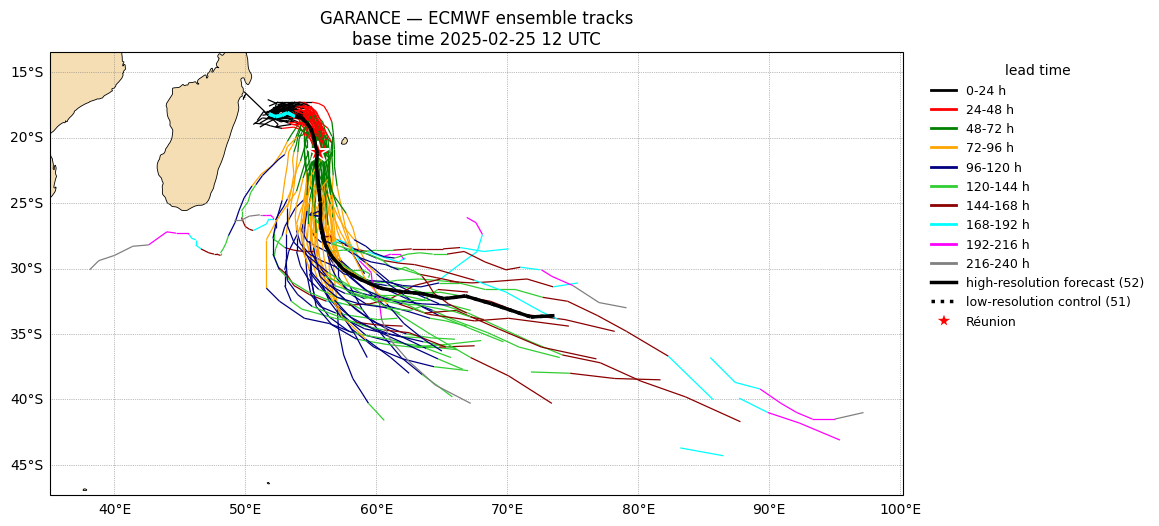

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import matplotlib.ticker as mticker

BAND_HOURS = 24   # one colour per 24 hours of lead time
COLOURS = ["black", "red", "green", "orange", "navy",             # 0-120 h
           "limegreen", "darkred", "cyan", "magenta", "grey"]     # 120-2400 h


HRES, CONTROL = 0, 1   # ensembleForecastType: high-resolution forecast, low-res control


def member_of(df, forecast_type):
    """Member number carrying one ensembleForecastType, or None if the run has none."""
    members = df.loc[df.ensembleForecastType == forecast_type, "ensembleMemberNumber"]
    return int(members.iloc[0]) if len(members) else None


def centre_longitude(df):
    """The longitude a map of these tracks should be centred on.

    Taken as a circular mean. A storm near the date line has longitudes at both
    ends of the -180..180 range, and a plain average of those would land on the
    far side of the planet.
    """
    radians = np.radians(df.longitude.dropna().to_numpy())
    return float(np.degrees(np.arctan2(np.sin(radians).mean(),
                                       np.cos(radians).mean())))


def unwrap_longitudes(longitude, centre):
    """Longitudes on a continuous scale around centre.

    A track crossing the date line jumps from +179 to -179, and a straight line
    between those two is drawn right across the map. Shifting every longitude
    into the 360-degree window centred on the storm removes the jump.
    """
    return centre + (longitude - centre + 180) % 360 - 180


def track_extent(df, pad=3, inner=1.0):
    """Map extent around a set of tracks, with a margin of pad degrees."""
    low, high = (1 - inner) / 2, (1 + inner) / 2
    return [df.longitude.quantile(low) - pad, df.longitude.quantile(high) + pad,
            df.latitude.quantile(low) - pad, df.latitude.quantile(high) + pad]


def reporting_interval(df):
    """The usual spacing between reported positions, in hours."""
    gaps = []
    for _, track in df.groupby("ensembleMemberNumber"):
        reported = track.dropna(subset=["latitude", "longitude"])["step"].to_numpy()
        gaps += np.diff(reported).tolist()
    gaps = np.array([g for g in gaps if g > 0], dtype=int)
    return int(np.bincount(gaps).argmax()) if gaps.size else STEP_HOURS


def track_segments(track, max_gap_hours):
    """Segments between reported positions no more than max_gap_hours apart."""
    reported = track.dropna(subset=["latitude", "longitude"])
    if len(reported) < 2:
        return np.empty((0, 2, 2)), np.empty(0, dtype=int)
    steps = reported["step"].to_numpy()
    points = reported[["longitude", "latitude"]].to_numpy(dtype=float)
    keep = np.diff(steps) <= max_gap_hours
    segments = np.stack([points[:-1], points[1:]], axis=1)
    return segments[keep], steps[:-1][keep].astype(int)


def plot_tracks(df, max_hours=240, base_time=""):
    """Plot ensemble tropical cyclone tracks, coloured by forecast lead time."""
    df = df.copy()
    hres, control = member_of(df, HRES), member_of(df, CONTROL)
    df["step"] = df.groupby("ensembleMemberNumber").cumcount() * STEP_HOURS
    df = df[df["step"] <= max_hours]      # missing positions are kept, so gaps stay open

    # Draw in a frame centred on the storm, so a track crossing the date line
    # stays in one piece. Longitudes become offsets from that centre, which
    # makes the map projection itself the right transform for the track data.
    centre = centre_longitude(df)
    df["longitude"] = unwrap_longitudes(df.longitude, centre) - centre
    crs = ccrs.PlateCarree(central_longitude=centre)
    extent = track_extent(df)

    ax = plt.figure(figsize=(11, 9)).add_subplot(projection=crs)
    ax.set_extent(extent, crs=crs)
    ax.add_feature(cfeature.LAND, facecolor="wheat")
    ax.coastlines("50m", linewidth=0.6)
    if PLACE:
        ax.plot(PLACE[1], PLACE[0], marker="*", color="red", markersize=16,
                markeredgecolor="white", markeredgewidth=1.2,
                transform=ccrs.PlateCarree(), zorder=6)   # a real longitude
    grid = ax.gridlines(draw_labels=True, linewidth=0.5, color="grey", linestyle=":")
    grid.top_labels = grid.right_labels = False
    # the default locator labels almost nothing once the map spans the date line
    step = next(s for s in (2, 5, 10, 15, 20, 30, 45) if (extent[1] - extent[0]) / s <= 8)
    grid.xlocator = mticker.FixedLocator(np.arange(-180, 181, step))

    interval = reporting_interval(df)   # 6 h in modern files, 12 h in older ones

    for member, track in df.groupby("ensembleMemberNumber"):
        segments, starts = track_segments(track, interval)
        if not len(segments):
            continue
        bands = starts // BAND_HOURS
        if member in (hres, control):
            style = dict(colors=["cyan" if b == 0 else "black" for b in bands],
                         linewidths=2.5, zorder=6 if member == hres else 5)
            if member == control:
                style["linestyles"] = ":"
        else:
            style = dict(colors=[COLOURS[b % len(COLOURS)] for b in bands],
                         linewidths=0.9, zorder=3)
        ax.add_collection(LineCollection(segments, transform=crs, **style))

    key = [Line2D([], [], color=COLOURS[b % len(COLOURS)], linewidth=2,
                  label=f"{b * BAND_HOURS}-{(b + 1) * BAND_HOURS} h")
           for b in range(max_hours // BAND_HOURS)]
    if hres is not None:
        key.append(Line2D([], [], color="black", linewidth=2.5,
                          label=f"high-resolution forecast ({hres})"))
    if control is not None:
        key.append(Line2D([], [], color="black", linewidth=2.5, linestyle=":",
                          label=f"low-resolution control ({control})"))
    if PLACE:
        key.append(Line2D([], [], color="red", marker="*", markersize=13, linestyle="none",
                          markeredgecolor="white", markeredgewidth=1.2, label=PLACE_NAME))
    ax.legend(handles=key, title="lead time", fontsize=9, frameon=False,
              loc="upper left", bbox_to_anchor=(1.02, 1))

    ax.set_title(f"{df.longStormName.iloc[0].strip()} — ECMWF ensemble tracks"
                 f"\nbase time {base_time}")
    plt.show()


plot_tracks(df, base_time=f"{BASE:%Y-%m-%d %H} UTC")

The small island east of the tracks is Mauritius, and the red star marks Réunion - the island itself is hidden under the bundle of tracks. We can see that the 2025-02-25 12 UTC forecast shows Garance reaching the area around Réunion in around 48-72 hours. This is correct, as Garance made landfall on 28 February at 6 UTC - in 66 hours.

<div class="alert alert-block alert-info">
<b>Note:</b> A member reports a position only for as long as its own forecast still contains a recognisable cyclone. When the tracker loses the storm, the track stops there; if it finds the storm again a few steps later, the track resumes, leaving one or more steps with no position at all. This notebook draws every track segment by segment and skips any segment that has a missing position at either end, so those gaps stay open.
</div>

-----------------

## 3. How strong? The intensity forecast

> *"After 00:00 UTC on the 27th, the MFR upgraded the system to an intense cyclone while it was approximately 300 km north of Réunion, equivalent to a Category 3 hurricane on the Saffir-Simpson scale."*

> *"The atmospheric pressure in Saint-Denis, near the center of the eye, was 975 hPa, and 10-minute sustained winds were estimated at 85 knots (157 km/h)."*

Let's check the 25 February 12 UTC forecast run against the observed information.

The chart below is the cyclone intensity plot. The top panel converts every member's 10 m wind into a category and counts how many members fall into each one. The two lower panels show the spread of wind and central pressure at each step, with the control as a solid line and the ensemble mean as a dotted line. The red star marks what was actually observed at landfall.

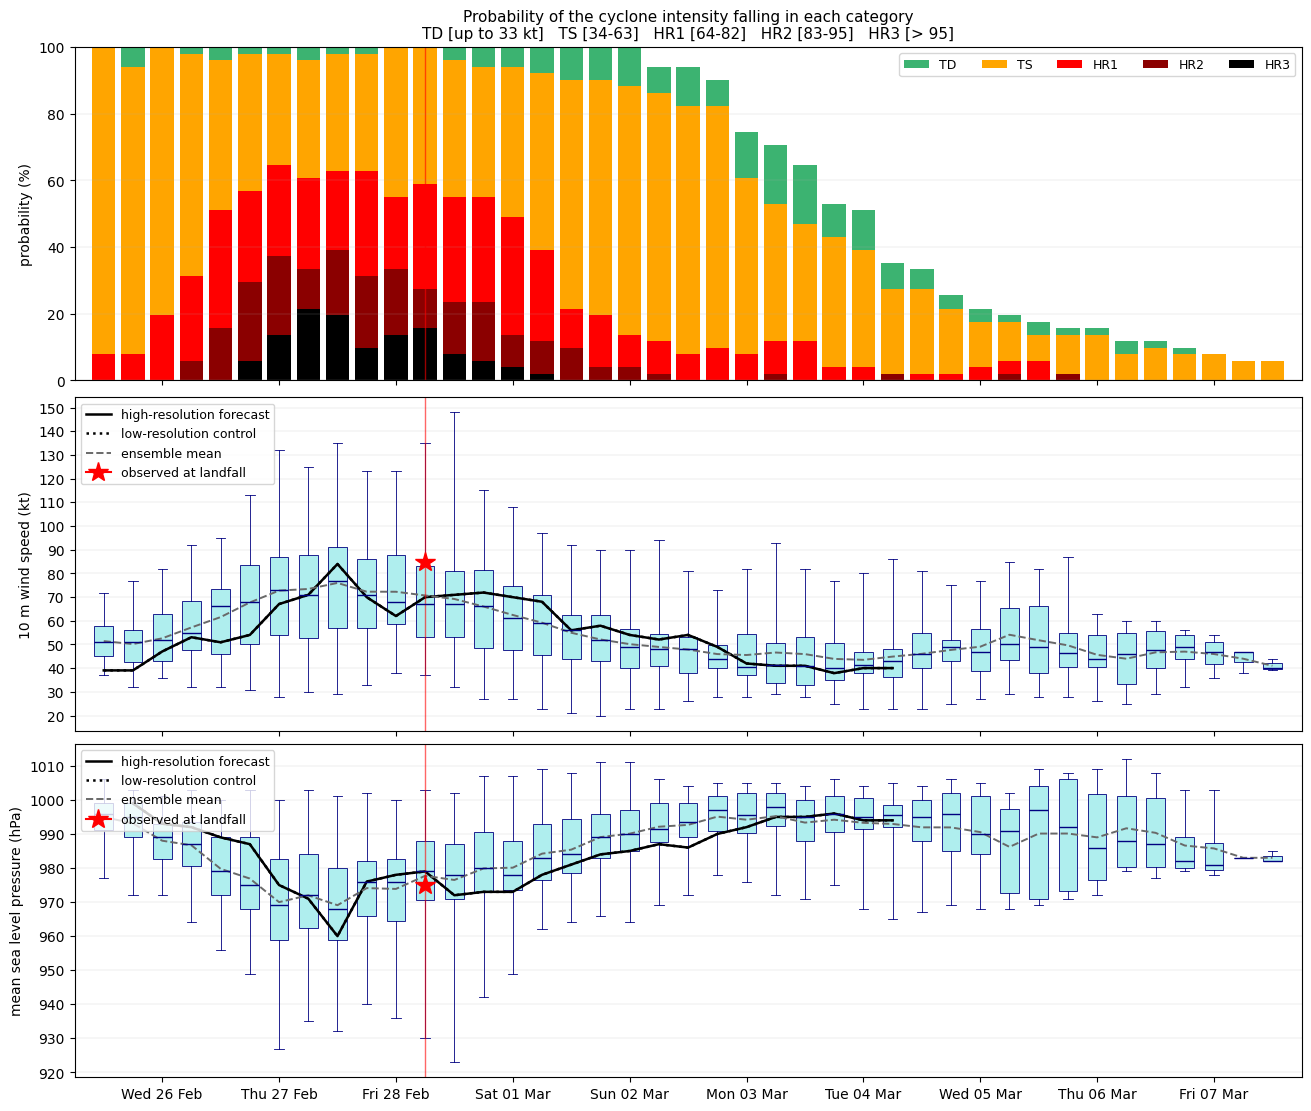

In [9]:
import matplotlib.dates as mdates
import pandas as pd
from matplotlib.ticker import MultipleLocator

MS_TO_KT = 1.94384
CATEGORIES = [("TD", "mediumseagreen"), ("TS", "orange"), ("HR1", "red"),
              ("HR2", "darkred"), ("HR3", "black")]
CATEGORY_EDGES = [-np.inf, 34, 64, 83, 96, np.inf]     # knots

centre = centre_track(storm)
wind = track_frame(storm, MAXWIND)


def intensity_panels(centre, wind, base_time, max_hours=240):
    """The three standard panels: category probability, wind spread, pressure spread."""
    base = datetime.strptime(base_time, "%Y%m%dT%H%M%S")
    valid = lambda s: base + timedelta(hours=int(s))
    centre = centre[centre.step <= max_hours].assign(
        mslp=lambda d: d.pressureReducedToMeanSeaLevel / 100)
    wind = wind[wind.step <= max_hours].assign(kt=lambda d: d.windSpeedAt10M * MS_TO_KT)
    steps = sorted(centre.step.unique())
    times = [valid(s) for s in steps]

    # The spread is the ensemble: the perturbed members plus the low-resolution
    # control. The high-resolution forecast is a separate run, so it is drawn on
    # top rather than counted into the boxes and the category shares.
    hres_no = member_of(centre, HRES)
    ens_centre = centre[centre.ensembleMemberNumber != hres_no]
    ens_wind = wind[wind.ensembleMemberNumber != hres_no]
    members = ens_centre.ensembleMemberNumber.nunique()

    fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True, layout="constrained")

    labels = [label for label, _ in CATEGORIES]
    counts = (ens_wind.dropna(subset=["kt"])
                  .assign(category=lambda d: pd.cut(d.kt, CATEGORY_EDGES,
                                                    right=False, labels=labels))
                  .groupby(["step", "category"], observed=False).size().unstack(fill_value=0)
                  .reindex(index=steps, columns=labels, fill_value=0))

    # strongest category on the baseline, weakest on top, as in the operational chart
    bars = {}
    bottom = np.zeros(len(steps))
    for label, colour in reversed(CATEGORIES):
        share = counts[label].to_numpy() / members * 100
        bars[label] = axes[0].bar(times, share, bottom=bottom, width=0.2,
                                  color=colour, label=label)
        bottom += share
    axes[0].set_ylabel("probability (%)")
    axes[0].set_ylim(0, 100)
    # the legend still reads TD -> HR3, like the title row
    axes[0].legend([bars[label] for label in labels], labels,
                   ncol=5, fontsize=9, loc="upper right")
    axes[0].set_title("Probability of the cyclone intensity falling in each category\n"
                      "TD [up to 33 kt]   TS [34-63]   HR1 [64-82]   HR2 [83-95]   HR3 [> 95]",
                      fontsize=11)

    box = dict(patch_artist=True, showfliers=False, whis=(0, 100), widths=0.16,
               boxprops=dict(facecolor="paleturquoise", edgecolor="navy", linewidth=0.6),
               medianprops=dict(color="navy"),
               whiskerprops=dict(color="navy", linewidth=0.6),
               capprops=dict(color="navy", linewidth=0.6))

    for ax, df, ens, column, ylabel, observed in (
            (axes[1], wind, ens_wind, "kt", "10 m wind speed (kt)", OBSERVED_WIND),
            (axes[2], centre, ens_centre, "mslp", "mean sea level pressure (hPa)", OBSERVED_MSLP)):
        ax.boxplot([ens.loc[ens.step == s, column].dropna() for s in steps],
                   positions=mdates.date2num(times), **box)
        for forecast_type, style, label in (
                (HRES, dict(linestyle="-", linewidth=1.8), "high-resolution forecast"),
                (CONTROL, dict(linestyle=":", linewidth=1.8), "low-resolution control")):
            number = member_of(df, forecast_type)
            if number is None:
                continue
            track = df[df.ensembleMemberNumber == number]
            ax.plot([valid(s) for s in track.step], track[column],
                    color="black", label=label, **style)
        ax.plot(times, [ens.loc[ens.step == s, column].mean() for s in steps],
                color="dimgrey", linestyle="--", linewidth=1.4, label="ensemble mean")
        if LANDFALL and observed is not None:
            ax.plot(LANDFALL, observed, marker="*", color="red", markersize=15, zorder=6,
                    label="observed at landfall")
        ax.set_ylabel(ylabel)
        ax.yaxis.set_major_locator(MultipleLocator(10))     # same tick step as the operational chart
        ax.legend(fontsize=9, loc="upper left")

    for ax in axes:
        if LANDFALL:
            ax.axvline(LANDFALL, color="red", linewidth=1, alpha=0.6)
        ax.grid(axis="y", linewidth=0.3, alpha=0.5)
        ax.xaxis.set_major_locator(mdates.DayLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
        ax.set_xlim(times[0] - timedelta(hours=6), times[-1] + timedelta(hours=6))
    return fig


fig = intensity_panels(centre, wind, BASE_TIME)
plt.show()

In [10]:
if LANDFALL is None:
    print("no landfall time in the settings, nothing to compare against")
else:
    # the file only holds 6-hourly steps, so use the one nearest to the landfall
    wanted = (LANDFALL - BASE).total_seconds() / 3600
    at_landfall = int(min(centre.step.unique(), key=lambda s: abs(s - wanted)))
    print(f"landfall is T+{wanted:.0f} h; comparing against the nearest step, T+{at_landfall} h")
    display(pd.DataFrame({
        "central pressure (hPa)": centre.loc[centre.step == at_landfall,
                                             "pressureReducedToMeanSeaLevel"].div(100).describe(),
        "10 m wind (kt)": wind.loc[wind.step == at_landfall,
                                   "windSpeedAt10M"].mul(MS_TO_KT).describe(),
    }).round(1))

landfall is T+66 h; comparing against the nearest step, T+66 h


,central pressure (hPa),10 m wind (kt)
count,52.0,52.0
mean,977.7,70.7
std,15.8,23.6
min,930.0,36.9
25%,970.8,53.6
50%,979.0,67.1
75%,988.0,83.0
max,1003.0,135.1


Read against the observations:

* **Pressure.** The observed 975 hPa at Saint-Denis falls inside the ensemble's interquartile range at T+66 h (970–988 hPa, median 979 hPa). Two and a half days ahead, the ensemble had the landfall pressure about right.
* **Wind.** The observed 85 kt sits just *above* the upper quartile of the ensemble (83 kt, median 67 kt) — inside the spread but towards its strong edge, so this run leaned a little weak.
* **Category.** For 27 February, the day the MFR upgraded Garance to an intense tropical cyclone, this run gave a **33–39% chance of HR2 or HR3** intensity and about 60% for hurricane force or above.

-----------------

### What we used, and what else is in the file

| Section | Question | Keys used |
| --- | --- | --- |
| 2 | Where might the storm go? | `latitude`, `longitude`, `ensembleMemberNumber` |
| 3 | Did the forecast converge? | positions from successive runs |
| 4 | How strong? | `pressureReducedToMeanSeaLevel`, `windSpeedAt10M` |

The message holds more than we used here. `effectiveRadiusWithRespectToWindSpeedsAboveThreshold`, together with `windSpeedThreshold` and `bearingOrAzimuth`, gives the reach of gale, storm and hurricane force winds in each of the four quadrants. So, one can draw the size of the storm rather than only its centre.

# Citation

Please cite the dataset via its DOI:

Lerner-Vilu, A., Iffrig, O., Prates, F., Zeizis, V., Vučković, M., Giusti, M., Altıntaş, Y. Ö., & Pidduck, E. (2026). ECMWF Tropical Cyclone Track Archive: IFS ensemble forecast tracks, 2010 onwards [Dataset]. European Center for Medium-range Weather Forecasts. https://doi.org/10.5281/zenodo.24303920

Dataset documentation: [ECMWF Tropical Cyclone Track Archive: User Documentation](https://confluence.ecmwf.int/spaces/DAC/pages/726489834/ECMWF+Tropical+Cyclone+Track+Archive+User+Documentation)

Licence: CC-BY 4.0 + ECMWF Terms of Use.